# 07 — Robustness & Persian stress tests

Stress-test slices for the deployed checkpoints, following the evaluation
checklist: cross-domain generalization, per-generator recall, document-length
stratification, Persian orthographic perturbations (ZWNJ, homoglyphs,
invisible characters), polished-AI (ai_revised) evasion and the formality
false-positive trap.

The **classical family** is used throughout — its feature matrices are cheap
to rebuild for perturbed and sliced text; the torch families are evaluated in
their own notebooks. AI-side documents come from the leak-free held-out set;
the human-side stress slices are documents the deployed models never saw
(v1 contained only blogs).

In [1]:
import warnings

import joblib
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import sparse
from scipy.special import expit
from sklearn.exceptions import InconsistentVersionWarning
from sklearn.metrics import roc_auc_score

from aitextd import metrics, paths, plots, splits
from aitextd.features import STYLE_FEATURE_NAMES
from aitextd.text import tokenize_persian_text

warnings.filterwarnings("ignore", category=InconsistentVersionWarning)

SEED = 42

In [2]:
linked = splits.v1_linked_dataset()
heldout = linked[linked["v1_split"] == "test"].reset_index(drop=True)
fresh_human = linked[(linked["v1_split"] == "") & (linked["label"] == "human")]
tokenized = splits.v1_tokens()

style_table = pd.read_parquet(paths.DATA_DIR / "style_features_v2.parquet")
vectorizer = joblib.load(paths.TFIDF_VECTORIZER_JOBLIB)
tfidf_dim = len(vectorizer.get_feature_names_out())


def model_probs(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return expit(model.decision_function(X))


def tokenize_texts(texts):
    """shekar-tokenized, whitespace-joined texts with progress output."""
    texts = list(texts)
    out, chunk = [], max(1, len(texts) // 5)
    for start in range(0, len(texts), chunk):
        out.extend(
            Parallel(n_jobs=-1)(delayed(tokenize_persian_text)(t) for t in texts[start : start + chunk])
        )
        print(f"tokenized {min(start + chunk, len(texts))}/{len(texts)}")
    return [" ".join(t) for t in out]


def frame_features(frame):
    """Joint TF-IDF (tokenized text) + style matrix for a v2 frame."""
    style = frame[["doc_id"]].merge(style_table, on="doc_id")[STYLE_FEATURE_NAMES].to_numpy()
    return sparse.hstack([vectorizer.transform(frame["joined_text"]), style], format="csr")


FILENAMES = {
    "svm": "svModel.joblib",
    "logreg": "logregModel.joblib",
    "naive_bayes": "nbModel.joblib",
    "random_forest": "rfModel.joblib",
    "gradient_boosting": "gbModel.joblib",
}
models = {mid: joblib.load(paths.model_path(fname)) for mid, fname in FILENAMES.items()}

heldout["joined_text"] = [" ".join(tokenized[row]) for row in heldout["v1_row"]]
X_held = frame_features(heldout)
y_held = heldout["label_binary"].to_numpy()

reports_clean, probs_clean = {}, {}
for mid, model in models.items():
    X_eval = X_held[:, :tfidf_dim] if mid in ("svm", "logreg") else X_held
    probs_clean[mid] = model_probs(model, X_eval)
    reports_clean[mid] = metrics.evaluation_report(y_held, probs_clean[mid])
print("clean held-out AUROC:", {mid: r["roc_auc"] for mid, r in reports_clean.items()})

clean held-out AUROC: {'svm': 0.9999, 'logreg': 0.9999, 'naive_bayes': 0.998, 'random_forest': 0.9993, 'gradient_boosting': 0.9995}


## Cross-domain generalization

Human documents of every domain the deployed models never saw (v1 contained
only blog prose), scored against the held-out AI documents. The AI side is
in-vocabulary for these checkpoints, so read the **FPR** panel — fresh human
prose flagged as AI — as the generalization signal, not the raw AUROC.

tokenized 11/56
tokenized 22/56
tokenized 33/56
tokenized 44/56
tokenized 55/56
tokenized 56/56
blog: 56 fresh human docs scored
tokenized 160/800
tokenized 320/800
tokenized 480/800
tokenized 640/800
tokenized 800/800
news: 800 fresh human docs scored
tokenized 160/800
tokenized 320/800
tokenized 480/800
tokenized 640/800
tokenized 800/800
encyclopedia: 800 fresh human docs scored
tokenized 160/800
tokenized 320/800
tokenized 480/800
tokenized 640/800
tokenized 800/800
legal_admin: 800 fresh human docs scored
tokenized 160/800
tokenized 320/800
tokenized 480/800
tokenized 640/800
tokenized 800/800
social_media: 800 fresh human docs scored
tokenized 12/63
tokenized 24/63
tokenized 36/63
tokenized 48/63
tokenized 60/63
tokenized 63/63
translated_subtitles: 63 fresh human docs scored


<Axes: title={'left': 'Cross-domain AUROC (fresh human vs held-out AI)'}>

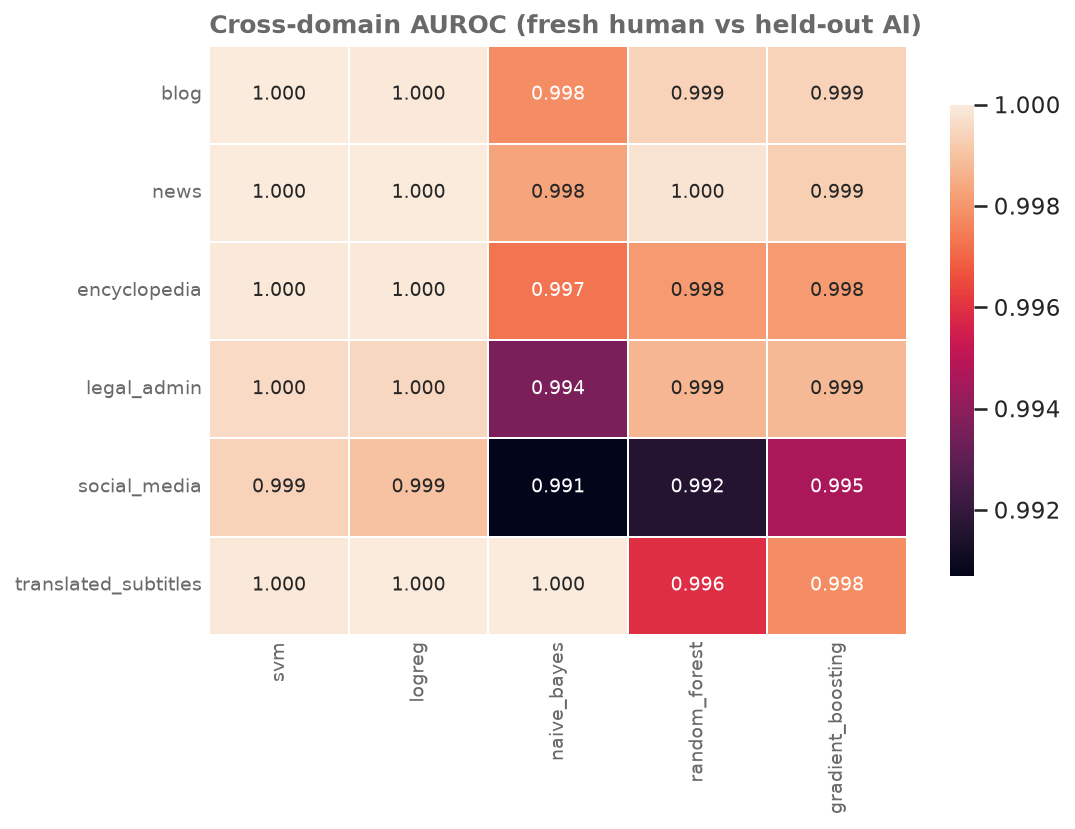

In [4]:
PER_DOMAIN = 800
domains = ("blog", "news", "encyclopedia", "legal_admin", "social_media", "translated_subtitles")
ai_mask = (heldout["label"] == "ai").to_numpy()
X_ai = X_held[ai_mask]
n_ai = int(ai_mask.sum())

cross_auc, cross_fpr = {}, {}
for domain in domains:
    pool = fresh_human[fresh_human["domain"] == domain]
    if pool.empty:
        continue
    pool = pool.sample(min(PER_DOMAIN, len(pool)), random_state=SEED).reset_index(drop=True)
    pool["joined_text"] = tokenize_texts(pool["text"])
    X_human = frame_features(pool)
    cross_auc[domain], cross_fpr[domain] = {}, {}
    for mid, model in models.items():
        human_slice = X_human[:, :tfidf_dim] if mid in ("svm", "logreg") else X_human
        ai_slice = X_ai[:, :tfidf_dim] if mid in ("svm", "logreg") else X_ai
        p_mix = np.concatenate([model_probs(model, human_slice), probs_clean[mid][ai_mask]])
        y_mix = np.concatenate([np.zeros(len(pool), dtype=int), np.ones(n_ai, dtype=int)])
        report = metrics.evaluation_report(y_mix, p_mix)
        cross_auc[domain][mid] = report["roc_auc"]
        cross_fpr[domain][mid] = report["fpr"]
    print(f"{domain}: {len(pool)} fresh human docs scored")

plots.heatmap(pd.DataFrame(cross_auc).T, "Cross-domain AUROC (fresh human vs held-out AI)")

<Axes: title={'left': 'Cross-domain FPR — fresh human prose flagged as AI'}>

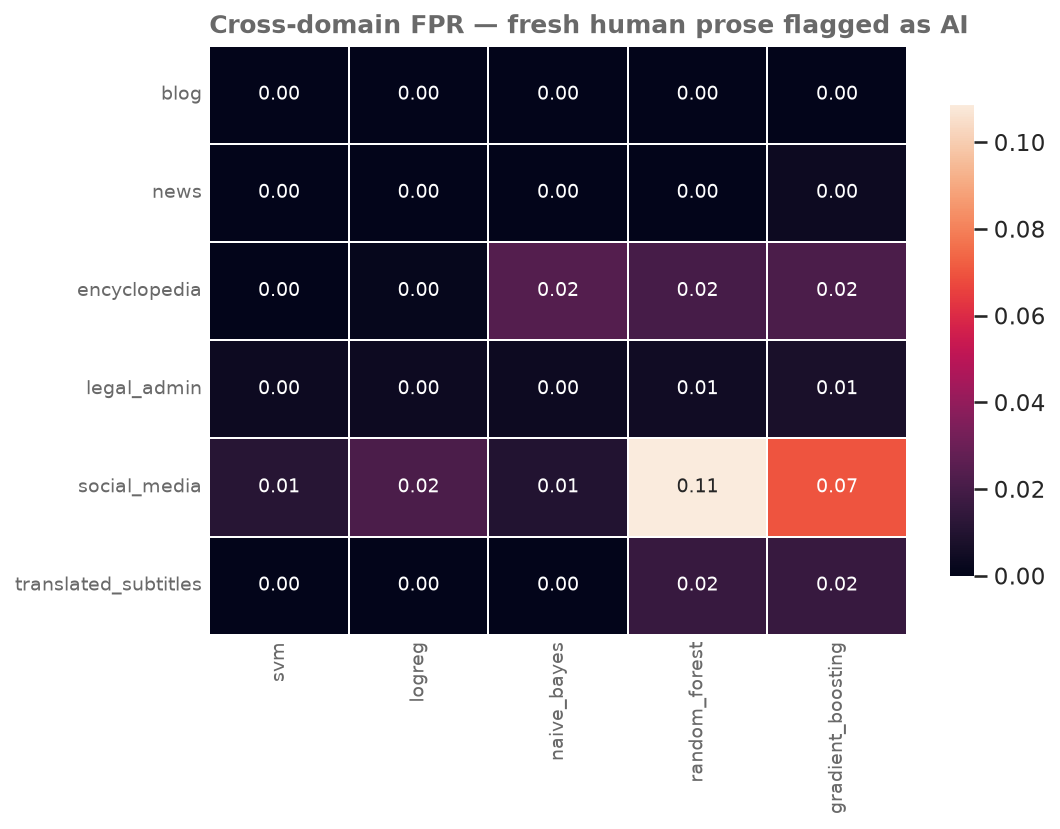

In [5]:
plots.heatmap(pd.DataFrame(cross_fpr).T, "Cross-domain FPR — fresh human prose flagged as AI", fmt=".2f")

## Recall per AI generator

The deployed checkpoints were trained on a fixed generator pool. Per-generator
recall on the held-out AI documents exposes which generators slip through —
the cross-generator weakness that retraining with held-out generators would
address.

89 generators total; top 12 by document count


<Axes: title={'left': 'AI recall by generator (held-out documents)'}, ylabel='generator'>

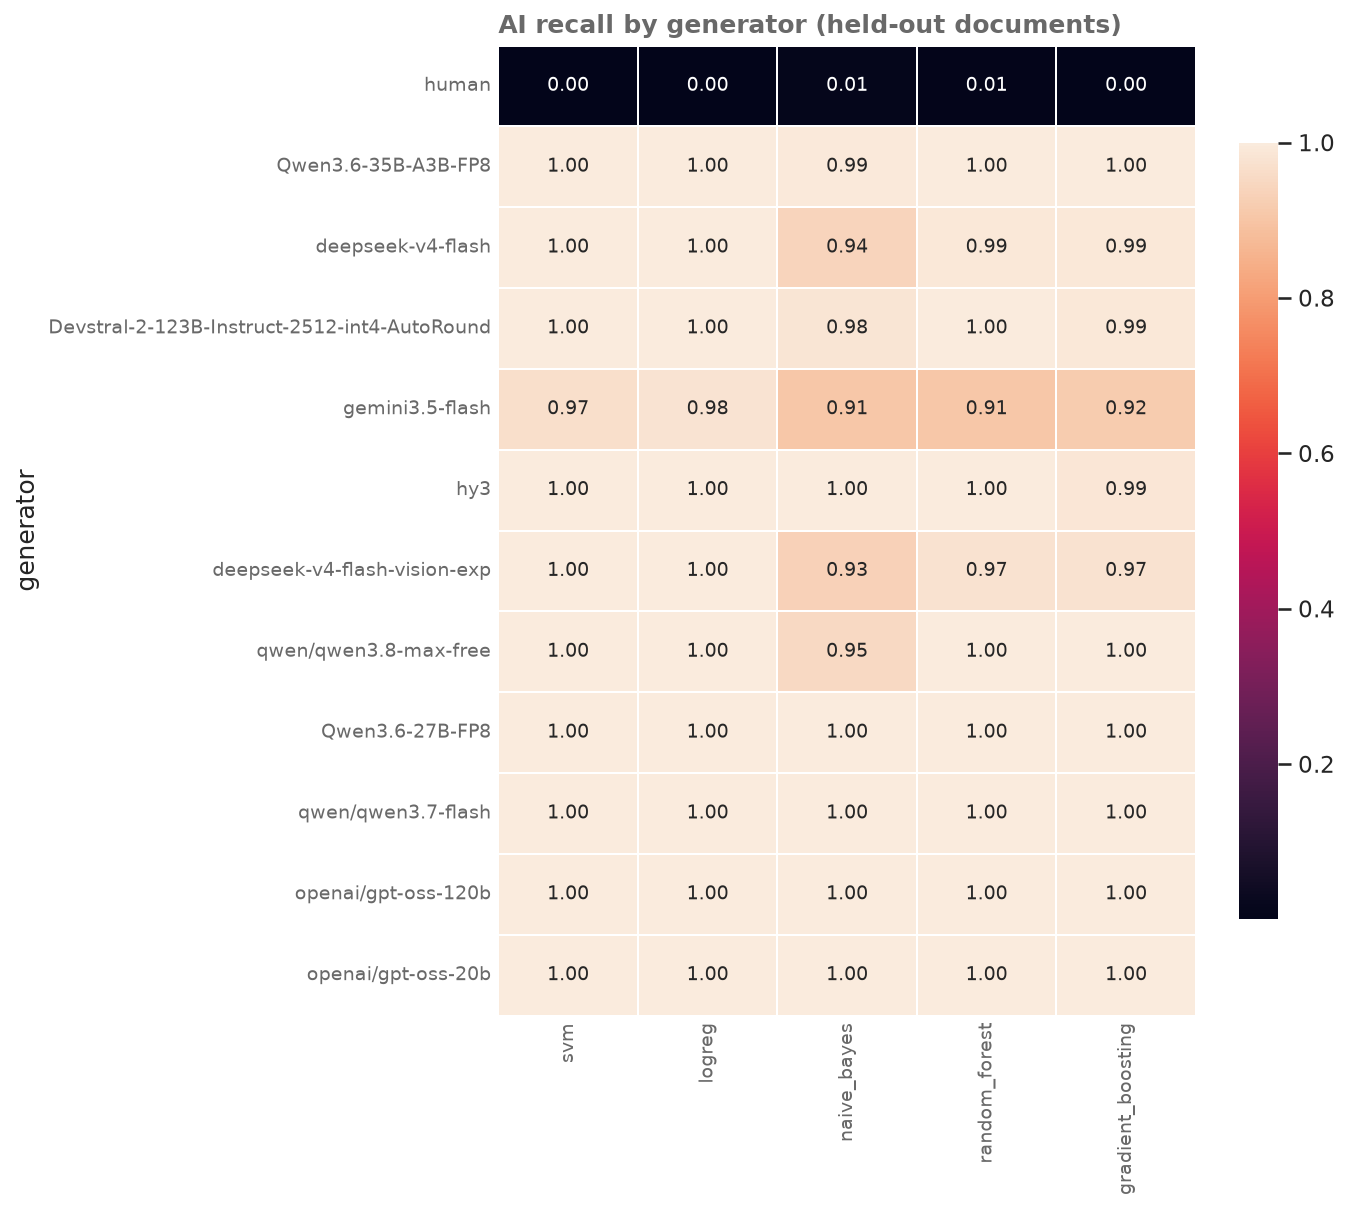

In [6]:
top_generators = heldout["generator"].value_counts().head(12).index
generator_recall = {}
for gen in top_generators:
    mask = (heldout["generator"] == gen).to_numpy()
    generator_recall[gen] = {
        mid: round(float((probs_clean[mid][mask] >= 0.5).mean()), 3) for mid in models
    }
recall_table = pd.DataFrame(generator_recall).T.rename_axis("generator")
print(f"{heldout['generator'].nunique()} generators total; top {len(top_generators)} by document count")
plots.heatmap(recall_table, "AI recall by generator (held-out documents)", fmt=".2f")

## Document-length stratification

Word-count buckets over the held-out set; the AUROC per bucket shows whether
short documents (little stylistic evidence) degrade the family.

short: 150 documents
medium: 657 documents
long: 765 documents
very long: 2484 documents


<Axes: title={'left': 'AUROC by document-length bucket (held-out set)'}>

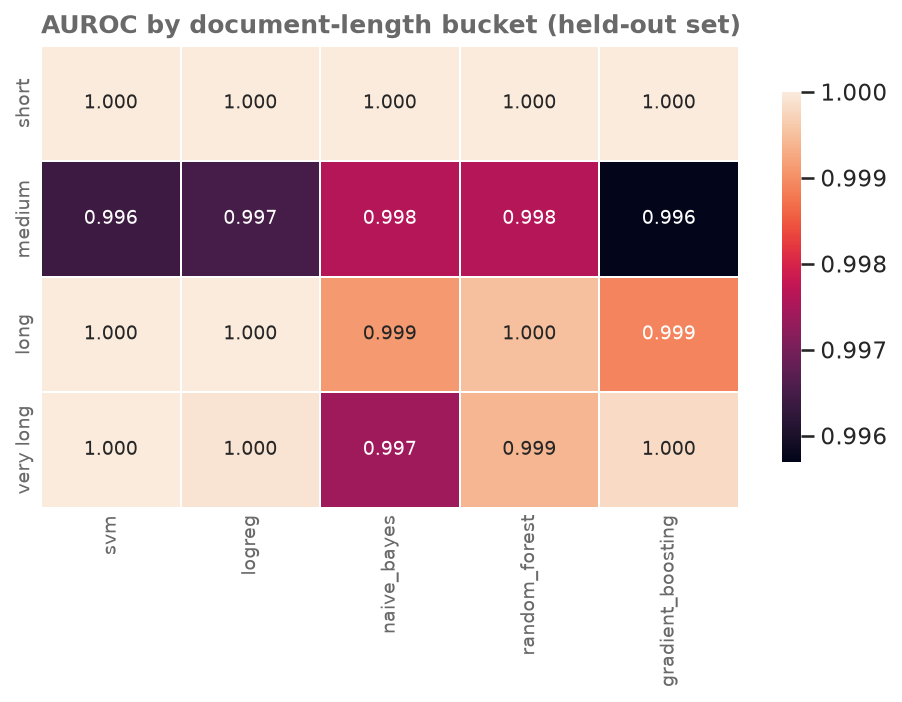

In [7]:
buckets = pd.cut(
    heldout["length_words"], bins=(0, 100, 300, 512, 100_000),
    labels=("short", "medium", "long", "very long"),
)
length_auc = {}
for bucket in buckets.cat.categories:
    mask = (buckets == bucket).to_numpy()
    if mask.sum() < 50:
        continue
    length_auc[bucket] = {
        mid: round(float(roc_auc_score(y_held[mask], probs_clean[mid][mask])), 4) for mid in models
    }
    print(f"{bucket}: {int(mask.sum())} documents")
plots.heatmap(pd.DataFrame(length_auc).T, "AUROC by document-length bucket (held-out set)")

## Persian orthographic perturbations

Deterministic typing-level attacks on a balanced 1,000-document subsample:
half-space (ZWNJ) dropped / spaced, Arabic homoglyphs (ی→ي، ک→ك) and injected
zero-width characters. The heatmap shows the AUROC change against the clean
baseline; the dumbbell shows each model's worst case.

In [8]:
ZWNJ = "\u200c"
HOMOGLYPHS = str.maketrans({"ی": "ي", "ک": "ك"})


def drop_zwnj(text):
    return text.replace(ZWNJ, "")


def zwnj_to_space(text):
    return text.replace(ZWNJ, " ")


def homoglyph(text):
    return text.translate(HOMOGLYPHS)


def zero_width(text):
    return text.replace(" ", "\u200b ")


PERT_SIZE = 1000
ai_pool = heldout[heldout["label"] == "ai"].sample(PERT_SIZE // 2, random_state=SEED)
human_pool = heldout[heldout["label"] == "human"].sample(PERT_SIZE // 2, random_state=SEED)
demo = pd.concat([ai_pool, human_pool]).sample(frac=1, random_state=SEED).reset_index(drop=True)
y_demo = demo["label_binary"].to_numpy()

demo_joined = tokenize_texts(demo["text"])
perturbations = {
    "clean": None,
    "zwnj_dropped": drop_zwnj,
    "zwnj_spaced": zwnj_to_space,
    "homoglyph_arabic": homoglyph,
    "zero_width": zero_width,
}
pert_auc = {}
for name, perturb in perturbations.items():
    if perturb is None:
        joined = demo_joined
    else:
        print(f"perturbing: {name}")
        joined = tokenize_texts([perturb(t) for t in demo["text"].astype(str)])
    X_pert = frame_features(demo.assign(joined_text=joined))
    pert_auc[name] = {}
    for mid, model in models.items():
        X_eval = X_pert[:, :tfidf_dim] if mid in ("svm", "logreg") else X_pert
        pert_auc[name][mid] = round(float(roc_auc_score(y_demo, model_probs(model, X_eval))), 4)

pert_frame = pd.DataFrame(pert_auc)
print(pert_frame.to_string())

tokenized 200/1000
tokenized 400/1000
tokenized 600/1000
tokenized 800/1000
tokenized 1000/1000
perturbing: zwnj_dropped
tokenized 200/1000
tokenized 400/1000
tokenized 600/1000
tokenized 800/1000
tokenized 1000/1000
perturbing: zwnj_spaced
tokenized 200/1000
tokenized 400/1000
tokenized 600/1000
tokenized 800/1000
tokenized 1000/1000
perturbing: homoglyph_arabic
tokenized 200/1000
tokenized 400/1000
tokenized 600/1000
tokenized 800/1000
tokenized 1000/1000
perturbing: zero_width
tokenized 200/1000
tokenized 400/1000
tokenized 600/1000
tokenized 800/1000
tokenized 1000/1000
                    clean  zwnj_dropped  zwnj_spaced  homoglyph_arabic  zero_width
svm                1.0000        0.9999       1.0000            0.9997      1.0000
logreg             1.0000        0.9999       1.0000            0.9996      1.0000
naive_bayes        0.9984        0.9981       0.9985            0.9931      0.9984
random_forest      0.9995        0.9995       0.9995            0.9990      0.9995
grad

<Axes: title={'left': 'AUROC change under Persian perturbations'}>

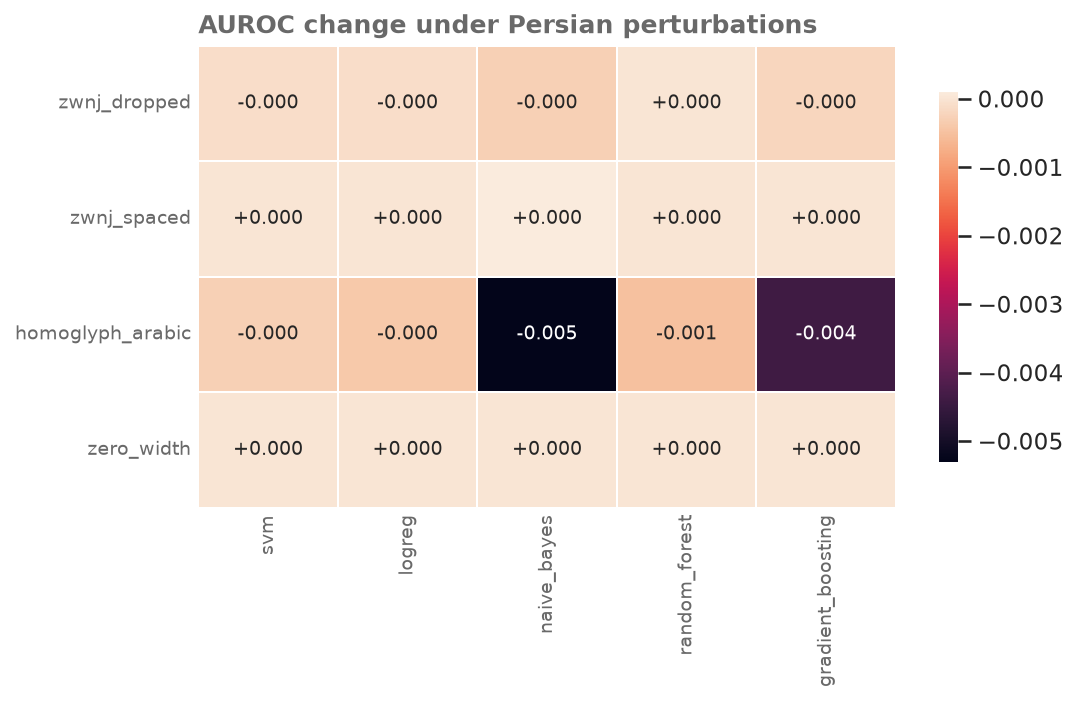

In [9]:
delta_frame = pert_frame.sub(pert_frame["clean"], axis=0).drop(columns="clean")
plots.heatmap(delta_frame.T, "AUROC change under Persian perturbations", fmt="+.3f")

<Axes: title={'left': 'Worst-case Persian perturbation — clean vs attacked AUROC'}, xlabel='AUROC'>

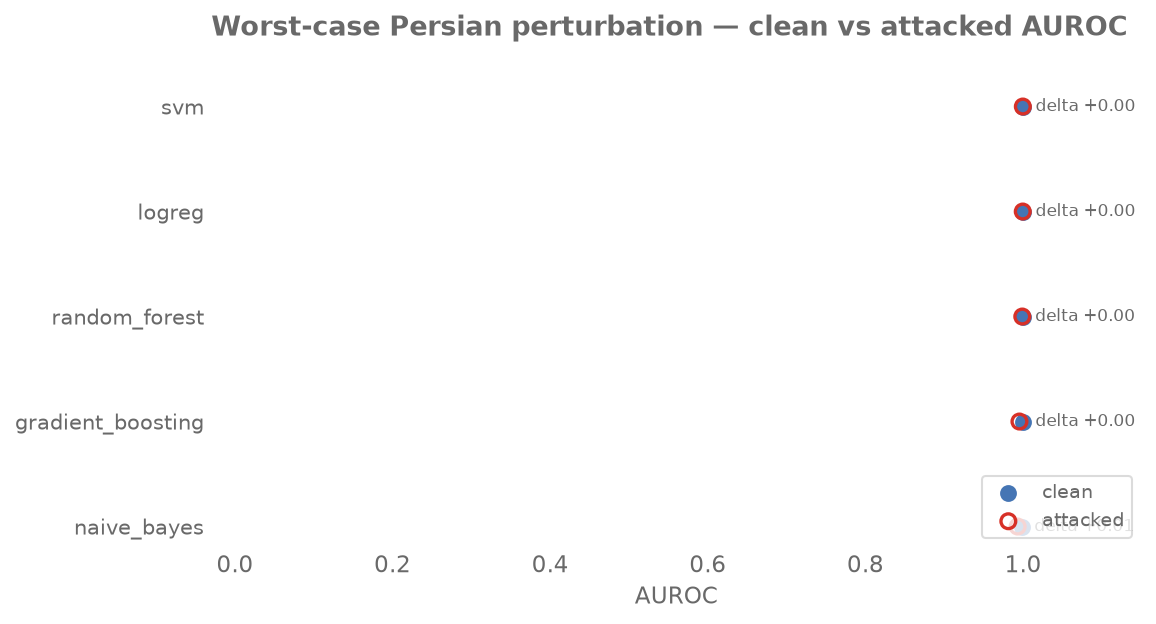

In [10]:
plots.dumbbell(
    pert_frame["clean"], pert_frame.drop(columns="clean").min(axis=1),
    "Worst-case Persian perturbation — clean vs attacked AUROC", "AUROC",
)

## Polished-AI (ai_revised) evasion

The `ai_revised` corpus is textually new (never part of v1) — paraphrased and
typographically perturbed AI. Recall on it measures evasion: how much AI
content slips through after humanization-style edits, against clean AI recall.

tokenized 200/1000
tokenized 400/1000
tokenized 600/1000
tokenized 800/1000
tokenized 1000/1000
tokenized 200/1000
tokenized 400/1000
tokenized 600/1000
tokenized 800/1000
tokenized 1000/1000
                   clean_ai_recall  polished_ai_recall
model                                                 
svm                         0.9962               0.001
logreg                      0.9957               0.002
naive_bayes                 0.9734               0.009
random_forest               0.9834               0.035
gradient_boosting           0.9810               0.041


<Axes: title={'left': 'AI recall: clean vs polished (ai_revised) documents'}, xlabel='recall'>

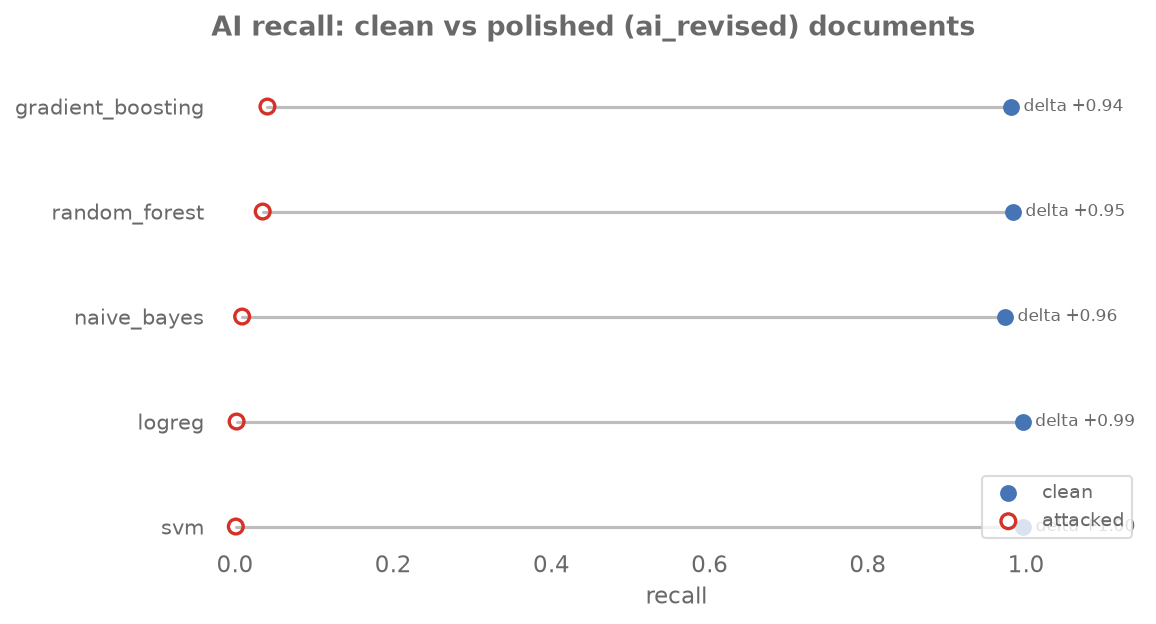

In [11]:
EVASION_SIZE = 1000
revised_pool = linked[linked["label"] == "ai_revised"].sample(
    min(EVASION_SIZE, int((linked["label"] == "ai_revised").sum())), random_state=SEED
).reset_index(drop=True)
human_pool = fresh_human.sample(min(EVASION_SIZE, len(fresh_human)), random_state=SEED).reset_index(drop=True)

revised_pool["joined_text"] = tokenize_texts(revised_pool["text"])
human_pool["joined_text"] = tokenize_texts(human_pool["text"])
X_revised, X_human2 = frame_features(revised_pool), frame_features(human_pool)

polished = {}
for mid, model in models.items():
    clean_ai_recall = reports_clean[mid]["recall"]
    revised_recall = float(
        (model_probs(model, X_revised[:, :tfidf_dim] if mid in ("svm", "logreg") else X_revised) >= 0.5).mean()
    )
    polished[mid] = {"clean_ai_recall": clean_ai_recall, "polished_ai_recall": round(revised_recall, 4)}

polished_table = pd.DataFrame(polished).T.rename_axis("model")
print(polished_table.to_string())
plots.dumbbell(
    polished_table["clean_ai_recall"], polished_table["polished_ai_recall"],
    "AI recall: clean vs polished (ai_revised) documents", "recall",
)

## Formality false-positive trap

False-positive rate on fresh human prose split by the marker-based formality
label — formal register is the classic trap for AI detectors.

tokenized 120/600
tokenized 240/600
tokenized 360/600
tokenized 480/600
tokenized 600/600
formal: 600 documents
tokenized 120/600
tokenized 240/600
tokenized 360/600
tokenized 480/600
tokenized 600/600
neutral: 600 documents
tokenized 120/600
tokenized 240/600
tokenized 360/600
tokenized 480/600
tokenized 600/600
informal: 600 documents


<Axes: title={'left': 'FPR on fresh human prose by formality'}>

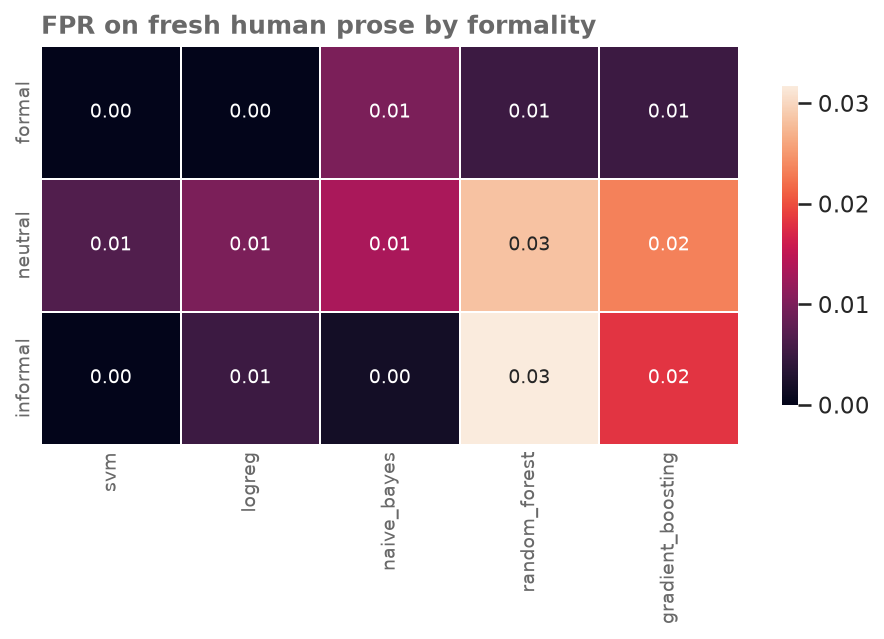

In [15]:
formality_fpr = {}
for formality in ("formal", "neutral", "informal"):
    pool = fresh_human[fresh_human["formality"] == formality]
    if len(pool) < 100:
        continue
    pool = pool.sample(min(600, len(pool)), random_state=SEED).reset_index(drop=True)
    pool["joined_text"] = tokenize_texts(pool["text"])
    X_form = frame_features(pool)
    formality_fpr[formality] = {}
    for mid, model in models.items():
        X_eval = X_form[:, :tfidf_dim] if mid in ("svm", "logreg") else X_form
        formality_fpr[formality][mid] = round(float((model_probs(model, X_eval) >= 0.5).mean()), 4)
    print(f"{formality}: {len(pool)} documents")

plots.heatmap(pd.DataFrame(formality_fpr).T, "FPR on fresh human prose by formality", fmt=".2f")

## Summary

- Cross-domain: read the FPR heatmap — unseen-domain human prose is where the
  deployed family is exposed, not the AI side.
- Per-generator recall + length buckets expose systematic blind spots.
- Persian perturbations and polished-AI evasion quantify attack surface; the
  formality heatmap is the false-positive audit.
- All slices run on the classical family for cheap feature rebuilds; the
  torch families should be re-run on these slices in their own notebooks when
  GPU-class hardware is available.